# Saatlik bisiklet kiralama tahmini: günün durumu ağa nasıl verilmeli?

[![Colab'da aç](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AxelXoket/neuromodulated-bike-demand/blob/main/bike_demand.ipynb)

UCI Bike Sharing verisinde (Washington, 2011-2012, saatlik) kiralama sayısını tahmin ediyorum. Soru: günün durumu (haftanın günü, tatil, hava durumu) ağa sıradan bir girdi olarak mı verilmeli, yoksa gizli birimleri ölçekleyip kaydıran bir ayar sinyali (FiLM) olarak mı? Eşit parametreli dört sinir ağı ve iki klasik model aynı zaman bölmesinde karşılaştırılıyor.

Bu not defteri kayıtlı sonuçları (`results/`) okur ve grafikleri çizer; en sondaki hücre isterseniz bütün deneyi yeniden koşar. Rapor: `docs/rapor.pdf`. Kod: https://github.com/AxelXoket/neuromodulated-bike-demand

In [1]:
# Setup: in Colab the project is fetched from the public repository; locally it is already here.
import os
import subprocess
import sys

if not os.path.isdir("bike_demand"):
    if not os.path.isdir("neuromodulated-bike-demand"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/AxelXoket/neuromodulated-bike-demand.git"], check=True)
    os.chdir("neuromodulated-bike-demand")
sys.path[:0] = [os.getcwd(), os.path.join(os.getcwd(), "tools")]

import json

import pandas as pd
from IPython.display import Image, display

import figures
from bike_demand import data, models, train

pd.set_option("display.width", 120)

## 1. Veri

`casual` ve `registered` toplamda `cnt`'yi verdiği için, `atemp` de `temp` ile neredeyse aynı (korelasyon 0,988) ve iki gün boyunca tek değerde takılı olduğu için çıkarılıyor. Bölme zamana göre: eğitim Ocak 2011-Haziran 2012, doğrulama Temmuz-Eylül 2012, test Ekim-Aralık 2012.

In [2]:
frame = data.load()
parts = data.split(frame)
print(f"{len(frame)} saat, {frame['dteday'].nunique()} gün, {data.missing_hours(frame)} saat hiç kayıtlı değil")
print({name: len(part) for name, part in parts.items()})
print("x (saatin kendisi):", len(data.INPUT_NAMES), "sütun; s (günün durumu):", len(data.STATE_NAMES), "sütun")
frame.head()

17379 saat, 731 gün, 165 saat hiç kayıtlı değil
{'train': 13003, 'validation': 2208, 'test': 2168}
x (saatin kendisi): 30 sütun; s (günün durumu): 11 sütun


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,hum,windspeed,cnt,time
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.81,0.0,16,2011-01-01 00:00:00
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.80,0.0,40,2011-01-01 01:00:00
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.80,0.0,32,2011-01-01 02:00:00
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.75,0.0,13,2011-01-01 03:00:00
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.75,0.0,1,2011-01-01 04:00:00


## 2. Veri keşfi

İş günlerinde iki tepe, hafta sonu tek bir öğleden sonra eğrisi var: günün türü eğrinin şeklini değiştiriyor. Sayılar sağa çarpık, bu yüzden modeller log(1 + kiralama) öğreniyor.

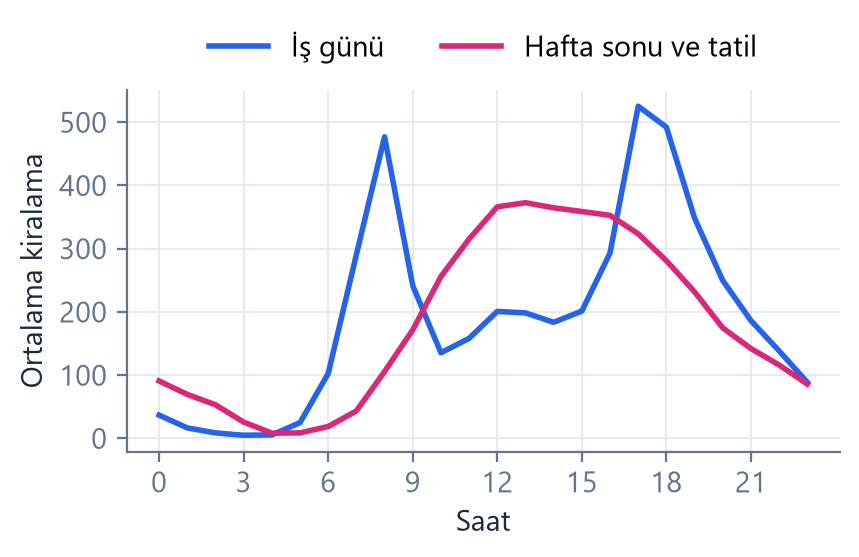

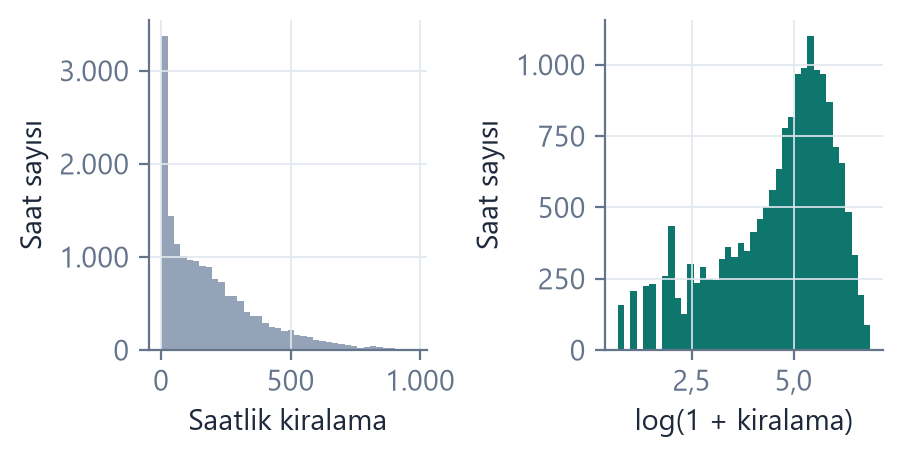

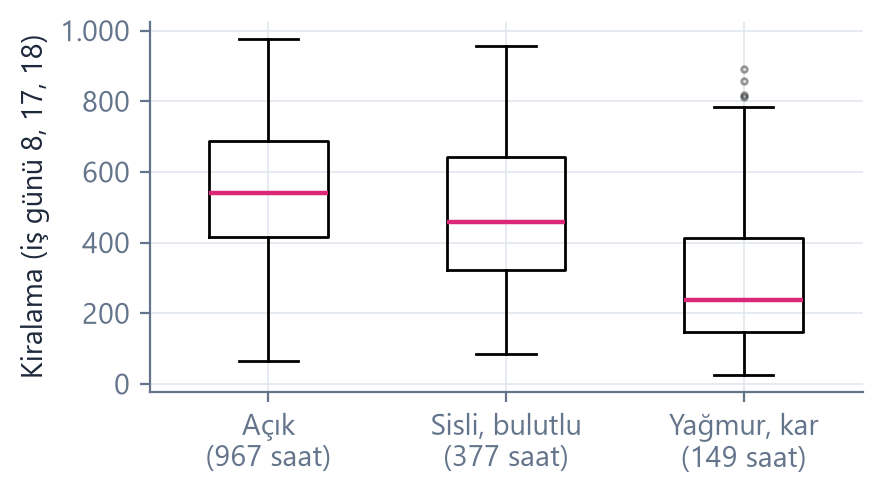

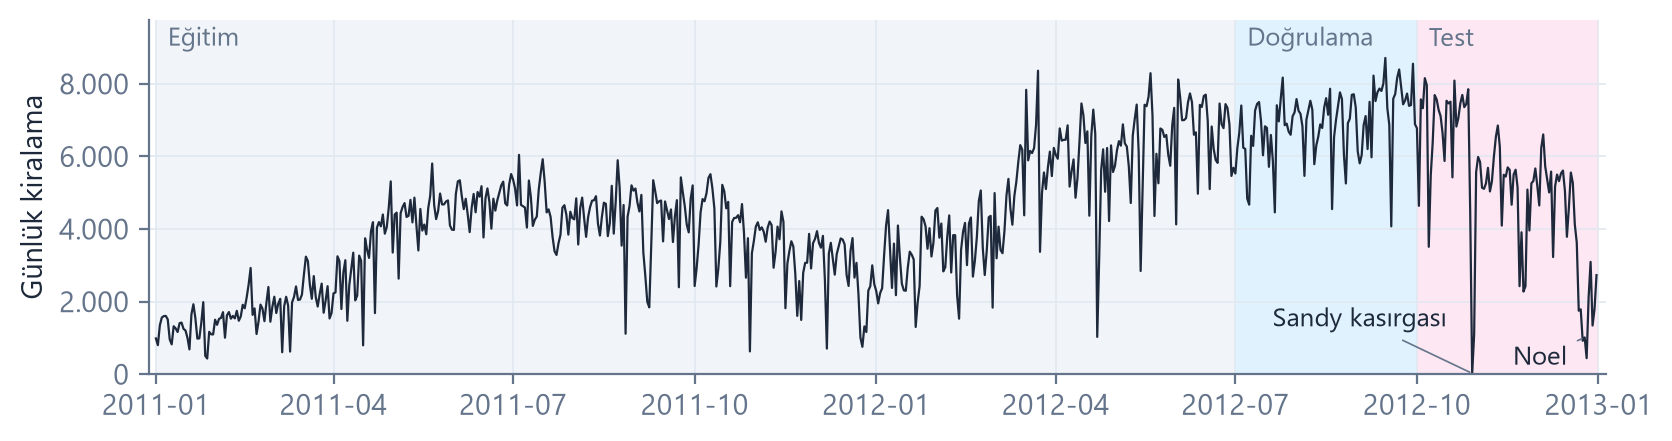

In [3]:
for path in (figures.hourly_profile(frame), figures.distribution(frame), figures.weather_effect(frame), figures.daily_series(frame)):
    display(Image(filename=str(path)))

## 3. Sonuçlar

Kayıtlı deney (RTX 5080, 10 seed) `results/metrics.json` içinde. Birincil metrik test RMSLE; ağlarda 10 seed ortalaması.

In [4]:
metrics = json.loads(open("results/metrics.json", encoding="utf-8").read())
mean = lambda value: value["mean"] if isinstance(value, dict) else value
table = pd.DataFrame({figures.LABELS[name]: {key: round(mean(value), 3) for key, value in metrics["test"][name].items()}
                      for name in figures.ORDER}).T
table[["rmsle", "rmse", "mae", "r2", "bias"]]

,rmsle,rmse,mae,r2,bias
Ridge,0.665,134.934,87.539,0.552,-57.486
Gradient boosting,0.433,70.713,44.806,0.877,-15.671
MLP durumsuz,0.661,118.219,79.279,0.656,-18.162
MLP durum girdide,0.437,72.212,45.747,0.872,-9.883
MLP yalnız kaydırma,0.438,72.443,46.481,0.871,-13.911
MLP FiLM,0.439,72.129,45.513,0.872,-2.489


In [5]:
pd.DataFrame({pair: {"fark": round(result["bootstrap"]["mean"], 4), "alt": round(result["bootstrap"]["low"], 4),
                     "üst": round(result["bootstrap"]["high"], 4)} for pair, result in metrics["comparisons"].items()}).T

,fark,alt,üst
concat - no-state,-0.2234,-0.2713,-0.1754
film - concat,0.0019,-0.0089,0.0123
film - shift,0.0014,-0.0074,0.0103
hgb - concat,-0.0044,-0.0237,0.0161
shift - concat,0.0005,-0.0068,0.0073


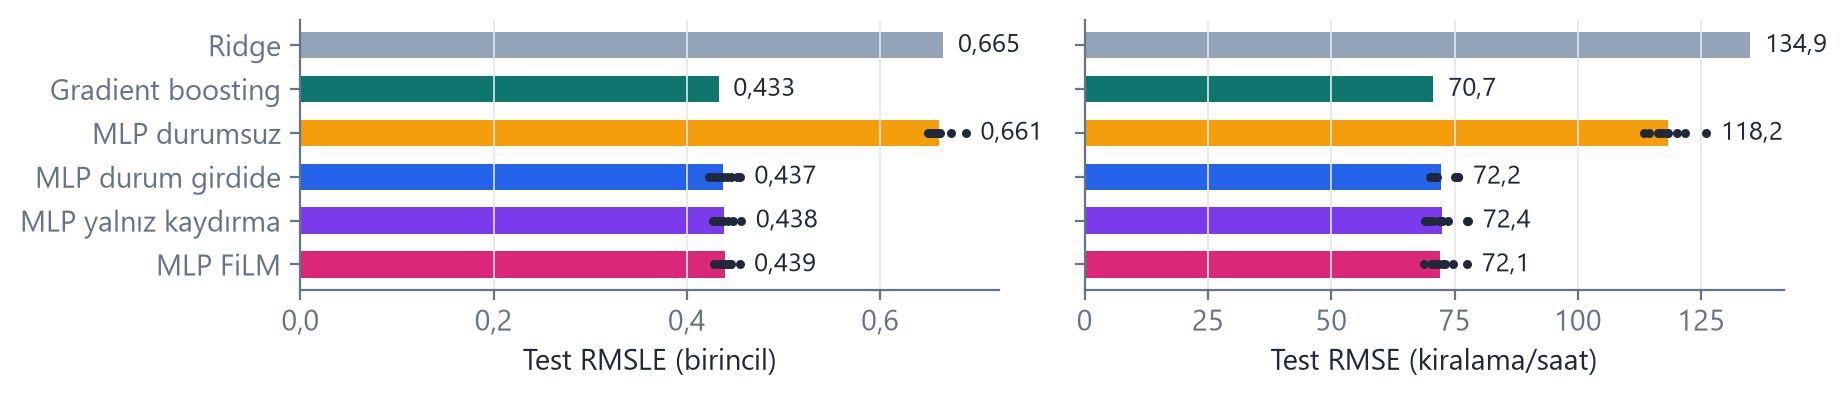

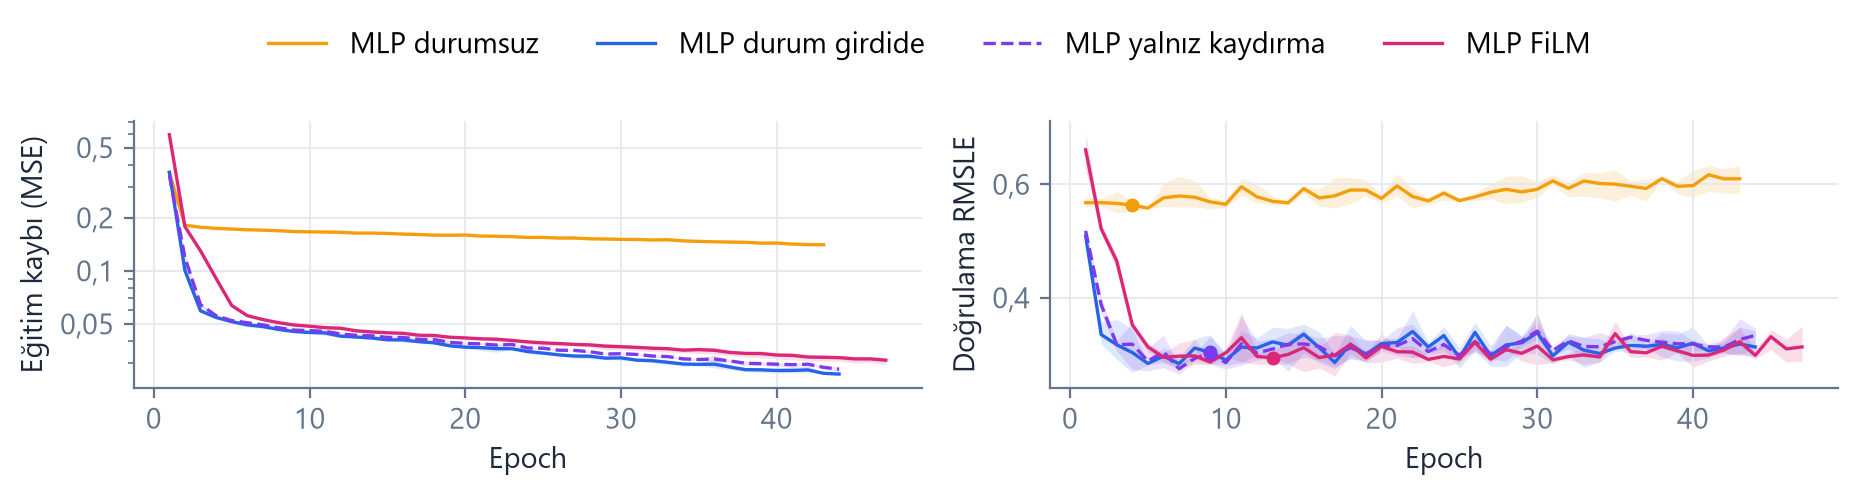

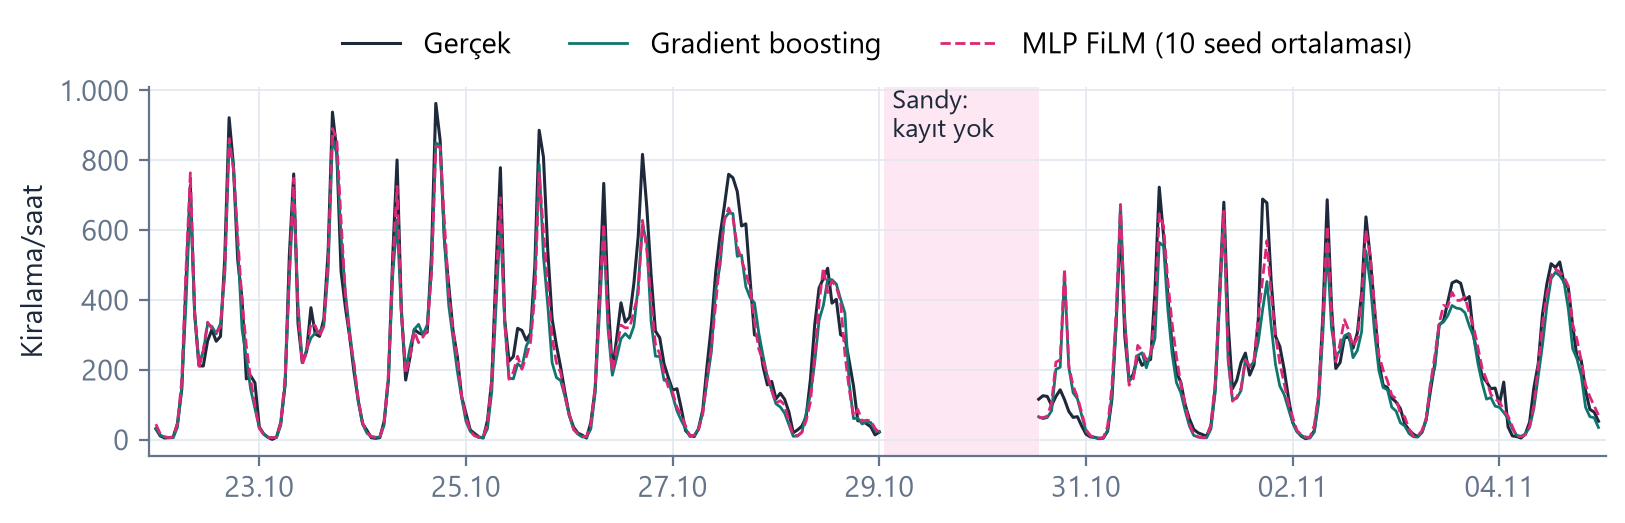

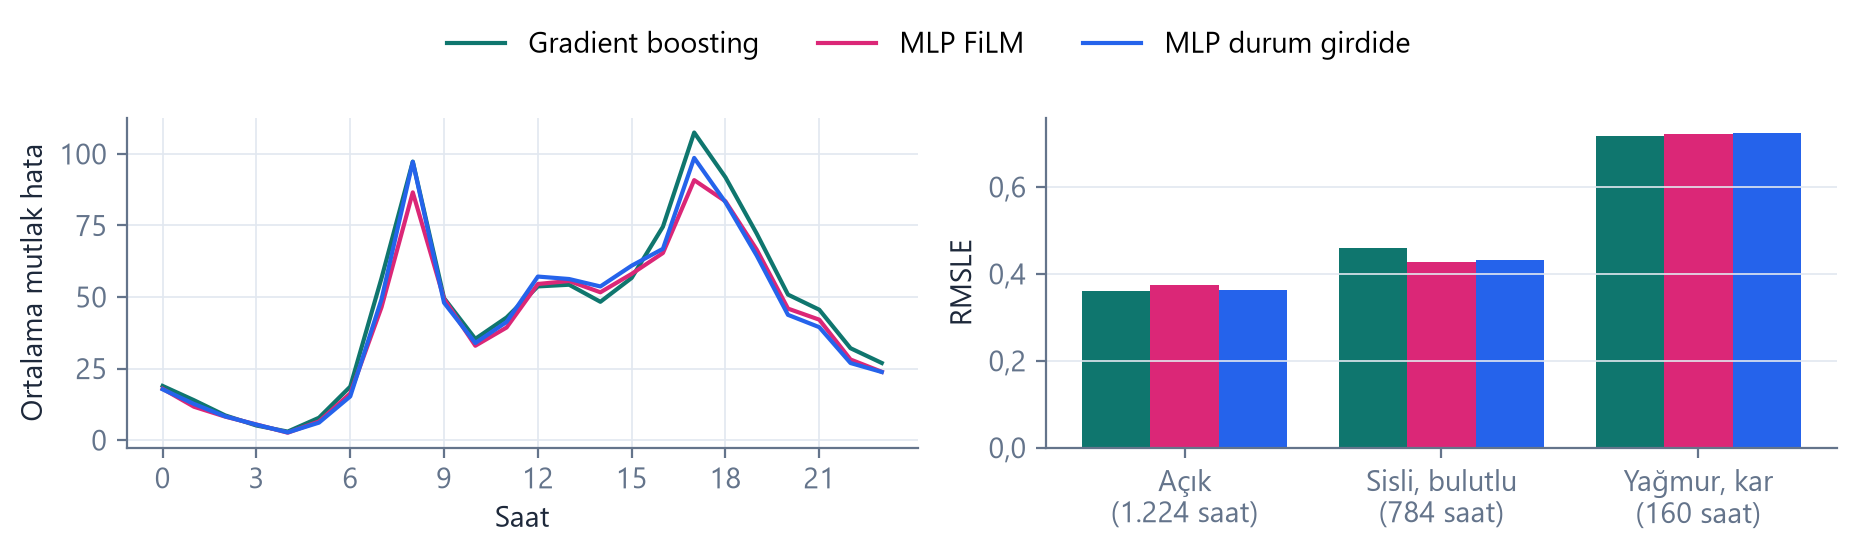

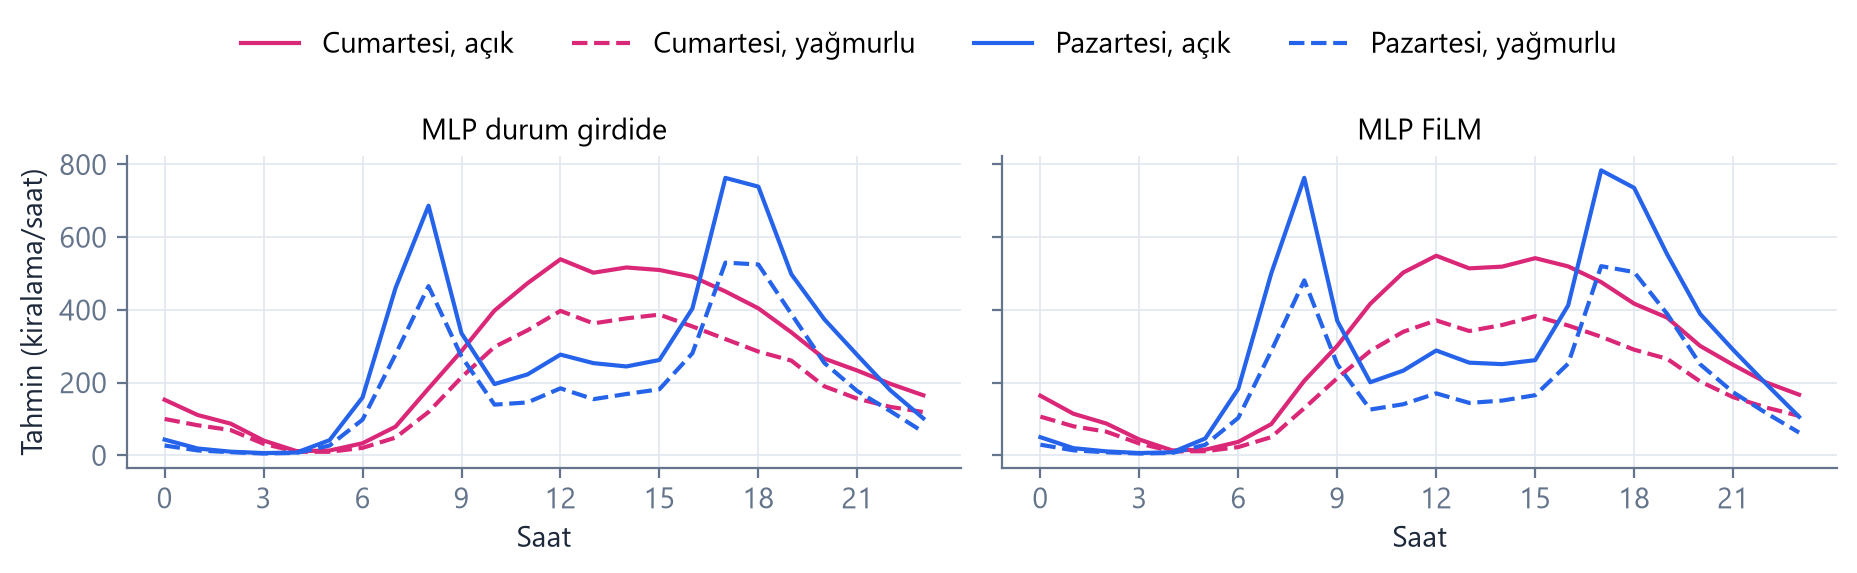

In [6]:
for path in figures.results_figures():
    display(Image(filename=str(path)))

## 4. Deneyi yeniden koşmak

`RUN_TRAINING = True` yapın. GPU varsa kullanılır; RTX 5080'de bütün deney yaklaşık 3,5 dakika sürdü, CPU'da daha uzun sürer. Farklı donanımda sayılar son basamaklarda kayabilir.

In [7]:
RUN_TRAINING = False
if RUN_TRAINING:
    train.deterministic()
    outcome = train.run(train.device())
    rerun = pd.DataFrame({name: {key: round(mean(value), 3) for key, value in outcome["metrics"]["test"][name].items()}
                          for name in figures.ORDER}).T
    display(rerun)